# 2 — Build the YOLO26 dataset

In [ ]:
%load_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").is_file():
    if ROOT.parent == ROOT:
        raise RuntimeError("run this notebook from inside the repository")
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
print("repo root:", ROOT)
print("python:  ", sys.version.split()[0], "->", sys.executable)

In [ ]:
import json
import shutil
import collections
import yaml

from IPython.display import Image, display

from perception.dataset import build_dataset
from perception.dataset import ExternalSource, merge_datasets

In [3]:
CAPTURE_ROOTS = [ROOT / "captures/curriculum_run"]
OUTPUT = ROOT / "datasets/curriculum_yolo26"
DATASET_CONFIG = ROOT / "configs/dataset.json"
ONTOLOGY = ROOT / "configs/ontology.json"
OVERWRITE = False

print(json.dumps(json.loads(DATASET_CONFIG.read_text()), indent=2, sort_keys=True))
for path in CAPTURE_ROOTS:
    if not (path / "annotations").is_dir():
        raise FileNotFoundError(f"{path} has no annotations/ — run notebook 01 first")

{
  "allow_empty_annotations": true,
  "box_mask_tolerance_pixels": 2.0,
  "class_mode": "semantic",
  "export_coco": true,
  "large_area_fraction": 0.1,
  "moving_speed_threshold": 0.05,
  "small_area_fraction": 0.01,
  "split": {
    "group_by": "episode",
    "random_seed": 20260725,
    "ratios": {
      "test": 0.1,
      "train": 0.7,
      "val": 0.2
    }
  },
  "visualization_samples_per_split": 4
}


In [4]:
if OVERWRITE and OUTPUT.exists():
    shutil.rmtree(OUTPUT)

if OUTPUT.exists():
    report = json.loads((OUTPUT / "validation_report.json").read_text())
    print("reusing existing dataset:", OUTPUT, "- set OVERWRITE = True to rebuild")
else:
    report = build_dataset(CAPTURE_ROOTS, OUTPUT, DATASET_CONFIG, ONTOLOGY)
    print(json.dumps(report, indent=2, sort_keys=True))

{
  "class_names": [
    "GoodGoal",
    "GoodGoalMulti",
    "jul_blocks",
    "DecayGoal",
    "DecayGoalEpEnding",
    "RipenGoal",
    "RipenGoalEpEnding",
    "BadGoal",
    "BadGoalMulti",
    "DecoyGoal",
    "Wall",
    "WallTransparent",
    "Ramp",
    "RampOld",
    "LightBlock",
    "HollowBox",
    "HeavyBlock",
    "CylinderTunnel",
    "CylinderTunnelTransparent",
    "DeathZone",
    "HotZone",
    "DataZone",
    "SignBoard",
    "SpawnerButton",
    "SpawnerContainerShort",
    "SpawnerDispenserTall",
    "SpawnerTree",
    "unknown_object"
  ],
  "coco_exported": true,
  "frames": 14841,
  "objects": 36748,
  "output_root": "/Users/hasan.zanouzi/Documents/perception-decision-execution-feedback/datasets/curriculum_yolo26",
  "split_counts": {
    "test": 1496,
    "train": 10672,
    "val": 2673
  },
  "validation_status": "passed",
  "warnings": 69368
}


Per-split counts and the leakage assertion.

In [5]:
splits = json.loads((OUTPUT / "splits.json").read_text())
validation = json.loads((OUTPUT / "validation_report.json").read_text())

print("status:", validation["status"], "| grouped by:", validation["group_by"])
print("frames checked:", validation["frames_checked"],
      "| objects checked:", validation["objects_checked"])
for split in ("train", "val", "test"):
    episodes = splits["episodes"][split]
    images = len(list((OUTPUT / "images" / split).glob("*.png")))
    print(f"  {split:5s} images={images:5d} episodes={len(episodes):3d} {sorted(episodes)}")

overlap = [
    (left, right, sorted(set(splits["episodes"][left]) & set(splits["episodes"][right])))
    for left, right in (("train", "val"), ("train", "test"), ("val", "test"))
]
print("episode leakage:", {f"{a}|{b}": shared for a, b, shared in overlap})
assert not any(shared for _, _, shared in overlap)
print("errors:", len(validation["errors"]))
print("warnings:", collections.Counter(item["code"] for item in validation["warnings"]))

status: passed | grouped by: episode
frames checked: 14841 | objects checked: 102793
  train images=10672 episodes=107 ['curriculum', 'curriculum-0001', 'curriculum-0005', 'curriculum-0006', 'curriculum-0007', 'curriculum-0009', 'curriculum-0011', 'curriculum-0012', 'curriculum-0014', 'curriculum-0015', 'curriculum-0016', 'curriculum-0019', 'curriculum-0020', 'curriculum-0021', 'curriculum-0022', 'curriculum-0023', 'curriculum-0024', 'curriculum-0026', 'curriculum-0027', 'curriculum-0028', 'curriculum-0029', 'curriculum-0030', 'curriculum-0031', 'curriculum-0032', 'curriculum-0034', 'curriculum-0035', 'curriculum-0036', 'curriculum-0038', 'curriculum-0039', 'curriculum-0040', 'curriculum-0041', 'curriculum-0043', 'curriculum-0044', 'curriculum-0047', 'curriculum-0048', 'curriculum-0049', 'curriculum-0050', 'curriculum-0052', 'curriculum-0053', 'curriculum-0054', 'curriculum-0056', 'curriculum-0057', 'curriculum-0058', 'curriculum-0059', 'curriculum-0060', 'curriculum-0061', 'curriculum

In [6]:
statistics = json.loads((OUTPUT / "statistics.json").read_text())
print(json.dumps(statistics, indent=2, sort_keys=True)[:4000])

{
  "frames": 14841,
  "frames_per_split": {
    "test": 1496,
    "train": 10672,
    "val": 2673
  },
  "motion": {
    "moving": 6712,
    "stationary": 27221,
    "unknown": 2815
  },
  "object_size": {
    "area_fraction": {
      "count": 36748,
      "max": 1.0,
      "mean": 0.060008442128095196,
      "median": 0.00726318359375,
      "min": 1.52587890625e-05
    },
    "buckets": {
      "large": 5386,
      "medium": 11069,
      "small": 20293
    },
    "thresholds": {
      "large_at_or_above": 0.1,
      "small_below": 0.01
    }
  },
  "objects": 36748,
  "objects_per_frame": {
    "histogram": {
      "0": 2272,
      "1": 3645,
      "10": 55,
      "11": 49,
      "12": 21,
      "13": 19,
      "14": 21,
      "15": 21,
      "16": 8,
      "17": 1,
      "18": 3,
      "19": 2,
      "2": 3161,
      "21": 1,
      "3": 2359,
      "4": 1327,
      "5": 684,
      "6": 388,
      "7": 396,
      "8": 251,
      "9": 157
    },
    "values": {
      "count": 14841,


In [7]:
label_files = sorted((OUTPUT / "labels").rglob("*.txt"))
classes = collections.Counter()
for path in label_files:
    for line in path.read_text().splitlines():
        if line.strip():
            classes[int(line.split()[0])] += 1

names = yaml.safe_load((OUTPUT / "data.yaml").read_text())["names"]
print("label files:", len(label_files), "| labelled objects:", sum(classes.values()))
for class_id, count in sorted(classes.items()):
    print(f"  {class_id:2d} {names[class_id]:18s} {count}")

example = next(path for path in label_files if path.read_text().strip())
print("\nexample label:", example.relative_to(OUTPUT))
print(example.read_text().splitlines()[0][:200], "...")
print("\ndata.yaml:\n" + (OUTPUT / "data.yaml").read_text())

label files: 14841 | labelled objects: 36748
   0 GoodGoal           2914
   1 GoodGoalMulti      6696
   2 jul_blocks         1496
   3 DecayGoal          235
   4 DecayGoalEpEnding  189
   5 RipenGoal          289
   6 RipenGoalEpEnding  228
   7 BadGoal            793
   8 BadGoalMulti       137
   9 DecoyGoal          771
  10 Wall               10642
  11 WallTransparent    2000
  12 Ramp               1080
  14 LightBlock         837
  15 HollowBox          505
  16 HeavyBlock         973
  19 DeathZone          827
  20 HotZone            590
  21 DataZone           441
  22 SignBoard          974
  23 SpawnerButton      217
  24 SpawnerContainerShort 933
  25 SpawnerDispenserTall 1385
  26 SpawnerTree        1596

example label: labels/test/curriculum-0003__000000.txt
0 0.480469 0.507812 0.480469 0.488281 0.484375 0.488281 0.484375 0.484375 0.488281 0.484375 0.488281 0.480469 0.511719 0.480469 0.511719 0.484375 0.515625 0.484375 0.515625 0.488281 0.519531 0.488281  ...

data.ya

Label overlays the converter rendered, so labels can be eyeballed before training.

train curriculum__000000.png


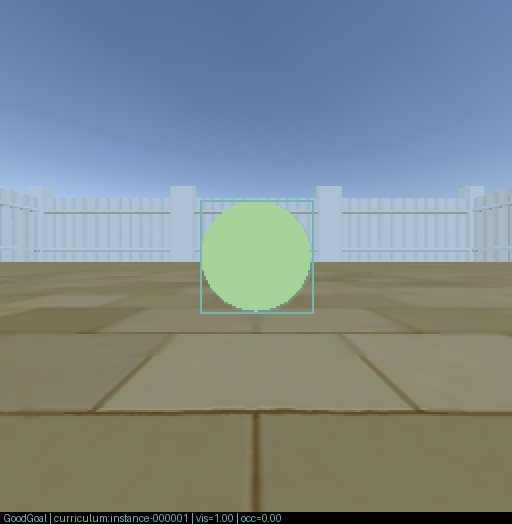

train curriculum__000001.png


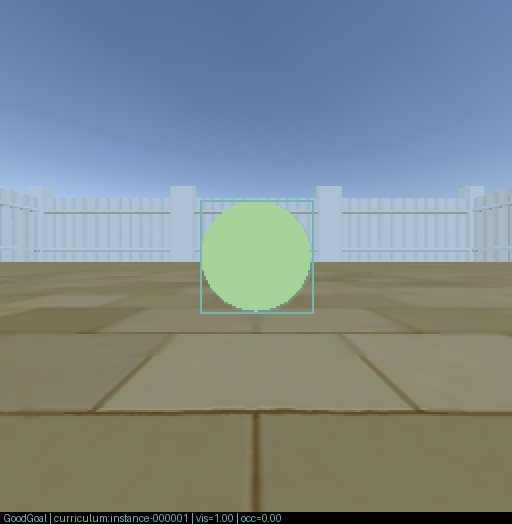

val curriculum-0002__000000.png


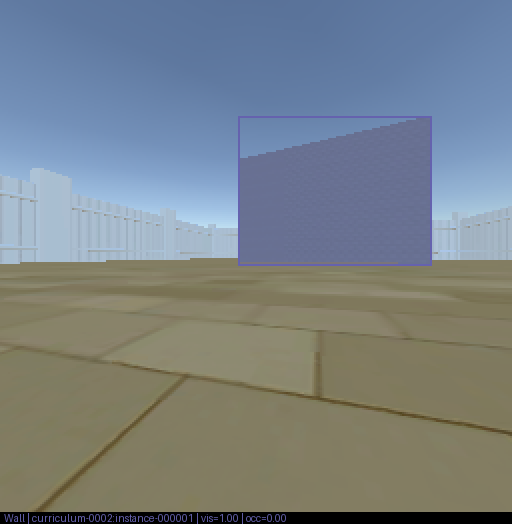

val curriculum-0002__000001.png


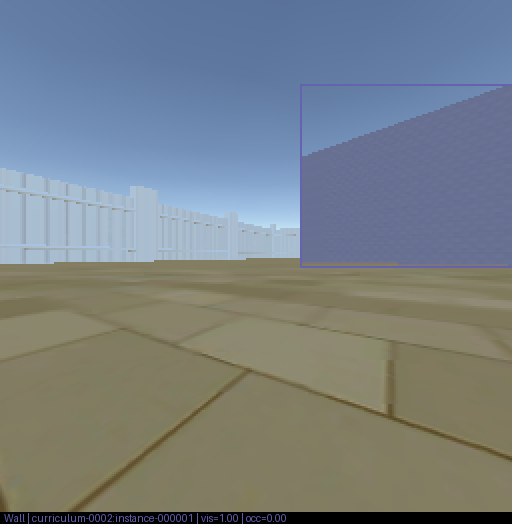

test curriculum-0003__000000.png


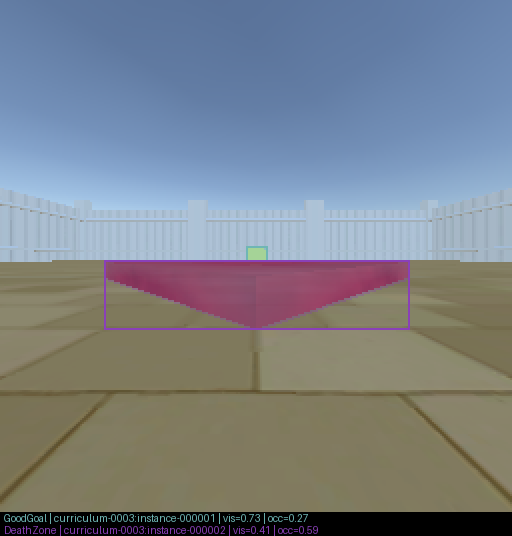

test curriculum-0003__000001.png


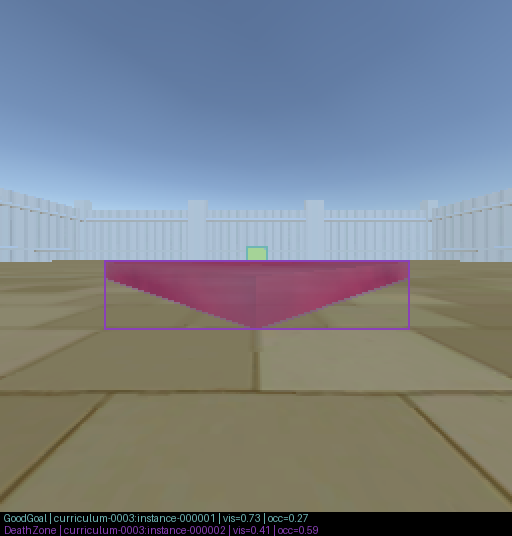

In [8]:
for split in ("train", "val", "test"):
    for path in sorted((OUTPUT / "visualizations" / split).glob("*"))[:2]:
        print(split, path.name)
        display(Image(filename=str(path)))

In [9]:
MERGED = ROOT / "datasets/animalai_merged"
EXTERNAL = [
    ExternalSource(
        name="roboflow_animalai",
        root=ROOT / "datasets/roboflow_yolo26",
        class_map={
            "BadGoal": "BadGoal",
            "GoodGoal": "GoodGoal",
            "GoodGoalMulti": "GoodGoalMulti",
            "Ramp": "Ramp",
            "Wall": "Wall",
        },
        group_pattern=r"^(\d+-\d+-\d+)",
    ),
]

if MERGED.exists() and not OVERWRITE:
    merge_report = json.loads((MERGED / "merge_report.json").read_text())
    print("reusing existing merged dataset:", MERGED)
else:
    if MERGED.exists():
        shutil.rmtree(MERGED)
    merge_report = merge_datasets(OUTPUT, EXTERNAL, MERGED)
print(json.dumps(merge_report, indent=2, sort_keys=True))

{
  "class_names": [
    "GoodGoal",
    "GoodGoalMulti",
    "jul_blocks",
    "DecayGoal",
    "DecayGoalEpEnding",
    "RipenGoal",
    "RipenGoalEpEnding",
    "BadGoal",
    "BadGoalMulti",
    "DecoyGoal",
    "Wall",
    "WallTransparent",
    "Ramp",
    "RampOld",
    "LightBlock",
    "HollowBox",
    "HeavyBlock",
    "CylinderTunnel",
    "CylinderTunnelTransparent",
    "DeathZone",
    "HotZone",
    "DataZone",
    "SignBoard",
    "SpawnerButton",
    "SpawnerContainerShort",
    "SpawnerDispenserTall",
    "SpawnerTree",
    "unknown_object"
  ],
  "groups": {
    "test": 49,
    "train": 206,
    "val": 66
  },
  "images": {
    "test": 3125,
    "train": 14954,
    "val": 4325
  },
  "leakage": "none",
  "objects_by_class": {
    "test": {
      "BadGoal": 1371,
      "BadGoalMulti": 34,
      "DataZone": 43,
      "DeathZone": 304,
      "DecayGoal": 27,
      "DecoyGoal": 113,
      "GoodGoal": 1416,
      "GoodGoalMulti": 2744,
      "HeavyBlock": 40,
      "Hollo

### Merging Datasets

In [10]:
merged_splits = json.loads((MERGED / "splits.json").read_text())
totals = collections.Counter()
by_source = collections.defaultdict(collections.Counter)
for split in ("train", "val", "test"):
    for line in (MERGED / "metadata" / f"{split}.jsonl").read_text().splitlines():
        record = json.loads(line)
        totals[split] += 1
        by_source[record["source"]][split] += 1

print("images per split:", dict(totals), "| total:", sum(totals.values()))
for source, counts in sorted(by_source.items()):
    print(f"  {source:20s} {dict(counts)}")
for split in ("train", "val", "test"):
    print(f"{split:5s} groups={len(merged_splits['episodes'][split]):4d}")

overlap = [
    set(merged_splits["episodes"][a]) & set(merged_splits["episodes"][b])
    for a, b in (("train", "val"), ("train", "test"), ("val", "test"))
]
assert not any(overlap), overlap
print("group leakage across splits: none")

images per split: {'train': 14954, 'val': 4325, 'test': 3125} | total: 22404
  capture              {'train': 10672, 'val': 2673, 'test': 1496}
  roboflow_animalai    {'train': 4282, 'val': 1652, 'test': 1629}
train groups= 206
val   groups=  66
test  groups=  49
group leakage across splits: none


### One picture per class

written: 24
missing (no instance anywhere): ['CylinderTunnel', 'CylinderTunnelTransparent', 'RampOld', 'unknown_object']


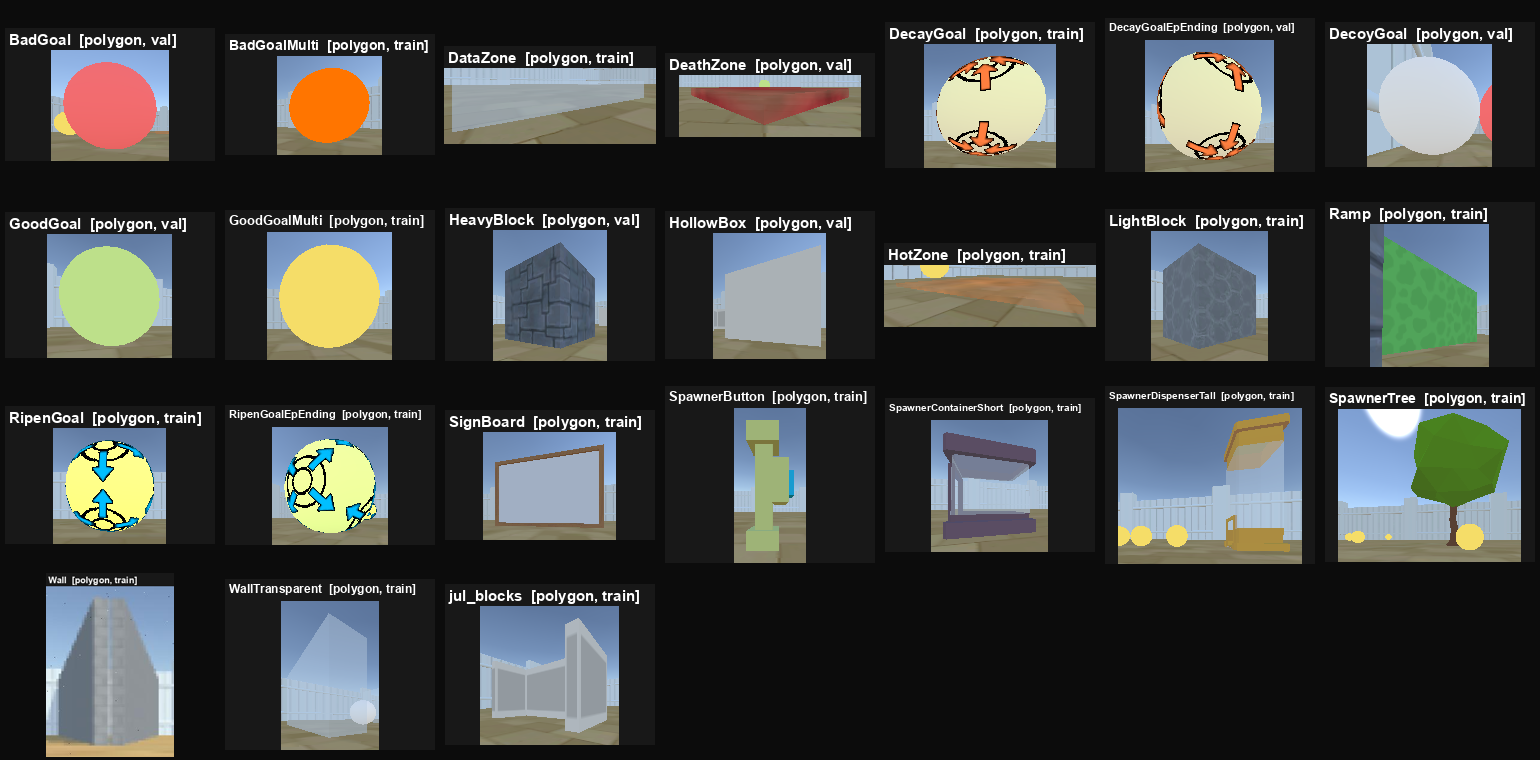

In [11]:
from perception.dataset import build_class_samples, build_contact_sheet

samples_report = build_class_samples(MERGED)
print("written:", len(samples_report["written"]))
print("missing (no instance anywhere):", samples_report["missing"] or "none")

sheet = build_contact_sheet(samples_report["output"])
display(Image(filename=str(sheet)))